# KuaiRec: EDA để hiểu dữ liệu và thiết kế feed gợi ý

Chạy từng ô từ trên xuống bằng **Shift + Enter**. Sau mỗi bảng/biểu đồ, đọc câu hỏi rồi thử sửa mã.
Notebook dùng dữ liệu thật đã có trong `study/kuairec_data/KuaiRec 2.0/data`.
Không tải dữ liệu, không cài thư viện, không sửa CSV gốc.

**Mục tiêu:** hiểu một dòng đại diện cho gì; đánh giá chất lượng dữ liệu; tìm phân bố hành vi,
độ phổ biến, thời gian và nội dung; từ đó chọn nhãn và feature cho content-based/hybrid.

**Cách chạy bằng VS Code**
1. Mở thư mục `C:/Users/Legion/Downloads/ThucHanh`, mở notebook trong `study/EDA`.
2. Chọn **Select Kernel → Python Environments → .venv**.
   Nếu chưa thấy, chọn interpreter `C:/Users/Legion/Downloads/ThucHanh/.venv/Scripts/python.exe`.
3. Chạy ô kiểm tra môi trường bên dưới, rồi chạy từng ô. Phần quét toàn bộ CSV có thể mất vài phút.
4. Nếu VS Code chưa có hỗ trợ notebook, cần extension Python và Jupyter của Microsoft.
   Notebook không yêu cầu JupyterLab hoặc chạy Docker.

**Nguồn:** [KuaiRec và schema](https://kuairec.com/),
[bài báo](https://arxiv.org/pdf/2202.10842),
[repository](https://github.com/chongminggao/KuaiRec).
Các kết quả bên dưới được tính từ CSV của bạn, không lấy số công bố thay cho kết quả.


Bản đã chạy bằng `.venv` của ThucHanh. Full scan và pair audit đã bật. Muốn tự chạy nhẹ hơn, dùng bản `01_KuaiRec_EDA.ipynb` chưa có output.


In [1]:
from pathlib import Path
import sys
import ast
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

print('Python:', sys.executable)
print('NumPy:', np.__version__, '| pandas:', pd.__version__)
pd.set_option('display.max_columns', 15)
pd.set_option('display.width', 120)
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.grid': True, 'grid.alpha': 0.2})


Python: c:\Users\Legion\Downloads\ThucHanh\.venv\Scripts\python.exe
NumPy: 2.5.3 | pandas: 3.0.5


## 1. Xác định file và phạm vi phân tích

`small_matrix`/`big_matrix`: một dòng là bản ghi phản hồi người dùng–video.
Tuy nhiên một dòng không luôn là một lần phát độc lập: ở đây có thể tự kiểm tra cặp trùng và đọc định nghĩa nhãn.
`item_daily_features`: một dòng là video–ngày. `user_features`, categories và caption là metadata.

Ban đầu đọc **100.000 dòng đầu của small_matrix** để học pandas nhanh.
Đây là phần đầu file, **không phải mẫu ngẫu nhiên được chọn để đại diện cho toàn bộ tập**.
`df.sample()` sau đó chỉ lấy ngẫu nhiên trong phần đầu này.


In [2]:
STUDY_DIR = Path(r'C:/Users/Legion/Downloads/ThucHanh/study')
DATA_DIR = STUDY_DIR / 'kuairec_data' / 'KuaiRec 2.0' / 'data'
N_PREVIEW = 100_000
CHUNK_SIZE = 250_000
RUN_FULL_SCAN = True       # False nếu hôm nay chỉ học phần cơ bản
RUN_PAIR_AUDIT = True     # True: đọc cặp user-video đầy đủ để kiểm tra density/overlap

assert DATA_DIR.exists(), f'Không tìm thấy dữ liệu: {DATA_DIR}'
files = pd.DataFrame([
    {'file': p.name, 'size_MB': p.stat().st_size / 1_000_000}
    for p in sorted(DATA_DIR.glob('*.csv'))
])
display(files.round(2))


,file,size_MB
0,big_matrix.csv,1083.52
1,item_categories.csv,0.11
2,item_daily_features.csv,85.86
3,kuairec_caption_category.csv,1.96
4,small_matrix.csv,406.16
5,social_network.csv,0.01
6,user_features.csv,0.74


In [3]:
df = pd.read_csv(DATA_DIR / 'small_matrix.csv', nrows=N_PREVIEW)
print('Phạm vi: phần đầu small_matrix, số dòng đọc =', len(df))
display(df.head())
display(df.tail())
display(df.sample(5, random_state=42))


Phạm vi: phần đầu small_matrix, số dòng đọc = 100000


,user_id,video_id,play_duration,video_duration,time,date,timestamp,watch_ratio
0,14,148,4381,6067,2020-07-05 05:27:48.378,20200705.0,1.593898e+09,0.722103
1,14,183,11635,6100,2020-07-05 05:28:00.057,20200705.0,1.593898e+09,1.907377
2,14,3649,22422,10867,2020-07-05 05:29:09.479,20200705.0,1.593898e+09,2.063311
3,14,5262,4479,7908,2020-07-05 05:30:43.285,20200705.0,1.593898e+09,0.566388
4,14,8234,4602,11000,2020-07-05 05:35:43.459,20200705.0,1.593899e+09,0.418364


,user_id,video_id,play_duration,video_duration,time,date,timestamp,watch_ratio
99995,174,7127,4556,9384,2020-07-17 23:21:11.74,20200717.0,1.594999e+09,0.485507
99996,174,2323,6901,12000,2020-07-17 23:22:10.941,20200717.0,1.594999e+09,0.575083
99997,174,9850,5701,4767,2020-07-17 23:23:23.363,20200717.0,1.594999e+09,1.195930
99998,174,2337,3662,4767,2020-07-17 23:27:49.65,20200717.0,1.595000e+09,0.768198
99999,174,3968,4710,6234,2020-07-17 23:33:48.879,20200717.0,1.595000e+09,0.755534


,user_id,video_id,play_duration,video_duration,time,date,timestamp,watch_ratio
75721,137,6283,5226,7570,2020-08-18 18:24:07.579,20200818.0,1.597746e+09,0.690357
80184,155,520,5820,10500,2020-07-18 14:40:10.16,20200718.0,1.595054e+09,0.554286
19864,36,3664,4421,11796,NaN,NaN,NaN,0.374788
76699,140,562,9411,9634,2020-07-16 16:49:46.02,20200716.0,1.594889e+09,0.976853
92991,169,288,12256,8900,2020-07-10 21:40:09.454,20200710.0,1.594388e+09,1.377079


## 2. Những lệnh pandas nên biết

| Lệnh | Câu hỏi |
|---|---|
| `head`, `tail`, `sample` | Dữ liệu trông như thế nào? |
| `shape`, `columns`, `dtypes`, `info` | Có bao nhiêu dòng/cột, kiểu gì, tốn RAM bao nhiêu? |
| `describe`, `quantile` | Giá trị thường gặp và đuôi phân bố ra sao? |
| `isna`, `duplicated`, `nunique` | Thiếu, trùng và độ đa dạng? |
| `value_counts`, `groupby`, `agg` | Nhóm nào phổ biến hoặc có hành vi khác? |
| `loc`, `query`, `sort_values` | Lọc và tìm bản ghi cần kiểm tra? |
| `merge`, `explode`, `pivot_table` | Nối metadata, mở danh sách tag, so sánh nhóm? |
| `pd.to_datetime`, `pd.cut` | Phân tích thời gian và chia khoảng số? |

NumPy giúp tính vector, phân vị, điều kiện và histogram. Phần lớn EDA dạng bảng dùng pandas.
ID là **định danh**, trung bình `user_id` không mang ý nghĩa sở thích.


In [4]:
print('Shape:', df.shape)
print('Columns:', df.columns.tolist())
df.info(memory_usage='deep')
display(df.dtypes.rename('dtype').to_frame())
display(df[['play_duration', 'video_duration', 'watch_ratio']].describe(
    percentiles=[0.01, 0.25, 0.5, 0.75, 0.95, 0.99]
))
display(df.select_dtypes(include=['object', 'string']).describe())


Shape: (100000, 8)
Columns: ['user_id', 'video_id', 'play_duration', 'video_duration', 'time', 'date', 'timestamp', 'watch_ratio']
<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 8 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   user_id         100000 non-null  int64  
 1   video_id        100000 non-null  int64  
 2   play_duration   100000 non-null  int64  
 3   video_duration  100000 non-null  int64  
 4   time            96213 non-null   str    
 5   date            96213 non-null   float64
 6   timestamp       96213 non-null   float64
 7   watch_ratio     100000 non-null  float64
dtypes: float64(3), int64(4), str(1)
memory usage: 8.2 MB


,dtype
user_id,int64
video_id,int64
play_duration,int64
video_duration,int64
time,str
date,float64
timestamp,float64
watch_ratio,float64


,play_duration,video_duration,watch_ratio
count,100000.000000,100000.000000,100000.000000
mean,8414.253940,14474.634040,0.886354
std,10487.756471,20430.580326,1.192066
min,0.000000,3067.000000,0.000000
1%,534.000000,4885.000000,0.019838
25%,5673.000000,7523.000000,0.465030
50%,7506.000000,9600.000000,0.762503
75%,9782.250000,11934.000000,1.110907
95%,16171.050000,44900.000000,1.947516
99%,28316.040000,139877.000000,3.274345


,time
count,96213
unique,96210
top,2020-07-29 05:56:07.42
freq,2


Ở đây <code>described()</code> hiển thị 100.000 dòng đầu của ***<code>small_matrix</code>***. Xét 3 cột : 
<ol>
  <li><code>play_duration</code> biểu thị thời gian xem được ghi nhận, đơn vị là mili giây</li>
  <li><code>video_duration</code> biểu thị độ dài của video, đơn vị là mili giây</li>
  <li><code>watch_ratio</code> biểu thị thời gian xem / độ dài video. \(VD\) : 0,5 = xem một nửa, 1 = xem một lần độ dài video, 2 = 2 lần</li>
</ol>


| Hàng | Ý nghĩa | Đọc từ bảng |
|---|---|---|
| `count` | Số giá trị không bị thiếu | Cả ba cột đều đủ 100.000 giá trị |
| `mean` | Trung bình | Thời gian xem khoảng **8,41 giây**, ratio trung bình **0,886** |
| `50%` | Trung vị: một nửa giá trị ≤ mức này | Một nửa bản ghi có thời gian xem ≤ **7,51 giây**, ratio ≤ **0,763** |
| `75%` | 75% giá trị ≤ mức này | Khoảng 25% bản ghi có ratio trên **1,111** |
| `95%` | 95% giá trị ≤ mức này | Chỉ khoảng 5% bản ghi có ratio trên **1,948** |
| `99%` | 99% giá trị ≤ mức này | Khoảng 1% bản ghi có ratio trên **3,274** |
| `max` | Giá trị lớn nhất | Có bản ghi ratio tới **111,68**, cần xem riêng |

\- Xét giá trị từ cột <code>watch_ratio</code> : 
- Phần lớn nằm quanh mức xem không hết hay xem hơn một lần độ dài video (<code>watch_ratio</code> ~ 1). 50% giá trị ratio nằm giữa 0,465 -> 111,1% độ dài video. Trung vị (median) 0,763 -> có 50% lượng người dùng có <code>watch_ratio</code> từ 0,763 trở lên.
- Phân phối lệch phải (right-skewed), thể hiện bởi giá trị trung bình (mean) = 0,886 cao hơn trung vị. Tức là có nhóm nhỏ người dùng trong 100.000 dòng này hoặc rất thích video hoặc là bot làm giá trị lệch. Độ lệch chuẩn = 1,192 cũng lớn hơn mean, tức là dữ liệu có tính dàn trải, có người xem video rồi thoát ngay, có người xem như thường và có người lặp đi lặp lại.
- Ngưỡng <code>watch_ratio > 2</code> chiếm một nhóm nhỏ. Xét phân vị 95% = 1,948 -> nhãn quan tâm mạnh chiếm không quá khoảng 5% trong lần quan sát này.


## 3. Chất lượng dữ liệu trước khi suy luận

Kiểm tra dữ liệu thiếu, số âm, video dài 0, giá trị không hữu hạn và tính nhất quán công thức.
`watch_ratio > 1` có thể do xem lại, không tự động là lỗi.
Cặp user–video trùng cũng chưa đủ để kết luận phải xóa, vì vậy cần xem toàn bộ bản ghi trước.
Kết quả ở đây chỉ áp dụng cho phần đầu file.


In [5]:
quality = pd.DataFrame({
    'missing': df.isna().sum(),
    'missing_pct': df.isna().mean() * 100,
    'nunique': df.nunique(dropna=True)
})
display(quality)
print('Dòng trùng hoàn toàn:', df.duplicated().sum())
print('Cặp user-video lặp (số dòng ngoài lần xuất hiện đầu):',
      df.duplicated(['user_id', 'video_id']).sum())

valid = (df.video_duration > 0) & df.play_duration.notna() & np.isfinite(df.watch_ratio)
bad_formula = ~np.isclose(
    df.loc[valid, 'watch_ratio'],
    df.loc[valid, 'play_duration'] / df.loc[valid, 'video_duration'],
    rtol=1e-5, atol=1e-6
)
display(pd.Series({
    'duration_zero_or_negative': (df.video_duration <= 0).sum(),
    'play_negative': (df.play_duration < 0).sum(),
    'watch_ratio_nonfinite': (~np.isfinite(df.watch_ratio)).sum(),
    'ratio_formula_mismatch_on_valid_rows': bad_formula.sum()
}).rename('count').to_frame())
display(df.nlargest(10, 'watch_ratio'))


,missing,missing_pct,nunique
user_id,0,0.000,31
video_id,0,0.000,3327
play_duration,0,0.000,18058
video_duration,0,0.000,2093
time,3787,3.787,96210
date,3787,3.787,63
timestamp,3787,3.787,96210
watch_ratio,0,0.000,98264


Dòng trùng hoàn toàn: 0
Cặp user-video lặp (số dòng ngoài lần xuất hiện đầu): 0


,count
duration_zero_or_negative,0
play_negative,0
watch_ratio_nonfinite,0
ratio_formula_mismatch_on_valid_rows,9


,user_id,video_id,play_duration,video_duration,time,date,timestamp,watch_ratio
99262,172,2344,982111,8794,NaN,NaN,NaN,111.679668
64151,131,2463,751286,7367,2020-07-26 06:24:20.744,20200726.0,1.595716e+09,101.979910
66048,131,7775,599264,6334,2020-08-31 17:51:22.83,20200831.0,1.598867e+09,94.610673
30575,55,4012,891965,9900,2020-07-20 11:56:49.655,20200720.0,1.595217e+09,90.097475
81451,155,9976,823262,10263,2020-08-06 14:32:50.502,20200806.0,1.596696e+09,80.216506
72603,136,10377,642241,8220,2020-08-29 16:16:43.296,20200829.0,1.598689e+09,78.131509
64853,131,2765,633238,9400,2020-08-04 12:54:25.783,20200804.0,1.596517e+09,67.365745
90988,166,7384,409729,6567,2020-08-02 05:46:48.63,20200802.0,1.596318e+09,62.392112
16480,24,7769,604729,9984,NaN,NaN,NaN,60.569812
21058,37,7113,411695,7500,2020-07-26 03:11:37.931,20200726.0,1.595704e+09,54.892667


Trong 100.000 dòng đầu không thiếu giá trị <code>user_id</code>, <code>video_id</code>, <code>play_duration</code> hay <code>video_duration</code>. Có 31 giá trị <code>user_id</code> ứng với 31 người dùng duy nhất trong 100.000 dòng đầu; 3327 video duy nhất trong 100.000 dòng đầu, 18.058 mức thời gian xem khác nhau, 2093 độ dài video khác nhau. Tuy nhiên có <code>time</code> thiếu 3787 dòng, phần còn lại có 96210 giá trị chuỗi thời gian khác nhau. <code>date</code> thiếu 3787 dòng, có 63 ngày khác nhau. <code>timestamp</code> thiếu 3787 dòng và có 96210 dấu thời gian khác nhau. <code>watch_ratio</code> không thiếu giá trị, có 98264 giá trị khác nhau.
\- Xét : 
- Số lượng người dùng khác nhau ít. 100.000 dòng đầu chỉ có 31 người dùng. (không đại diện cho cả tập)
- Xét số lượng video là 3327 nhưng có 2093 giá trị độ dài video. 
- Có 3 cột cùng thiếu 3787 giá trị. Quan sát lại -> đều thiếu trên cùng các dòng. Tức là không thể sử dụng giá trị ở hai cột còn lại để khôi phục thời gian cho 3787 dòng thiếu.

## 4. Nhãn phản hồi: xem nhiều có phải thích không?

`watch_ratio = play_duration / video_duration`. Bài báo dùng `watch_ratio > 2`
làm nhãn quan tâm mạnh. Bởi vì việc sử dụng chỉ số khác như lượt thích khiến dữ liệu bị thưa -> sử dụng nhãn này làm thay thế.
Xét thử ngưỡng 0.5, 1, 2 để thấy việc chọn nhãn thay đổi tỷ lệ positive thế nào.
Ở đây chưa xem cặp chưa quan sát là negative. Nếu thay nhãn, phải đánh giá lại mô hình.


,threshold,rule,positive_rows,positive_pct
0,0.5,watch_ratio > 0.5,72469,72.469
1,1.0,watch_ratio > 1.0,31682,31.682
2,2.0,watch_ratio > 2.0,4616,4.616


Phân vị NumPy: {'p50': np.float64(0.7625034112948356), 'p90': np.float64(1.5587513852036836), 'p99': np.float64(3.274345135311373)}


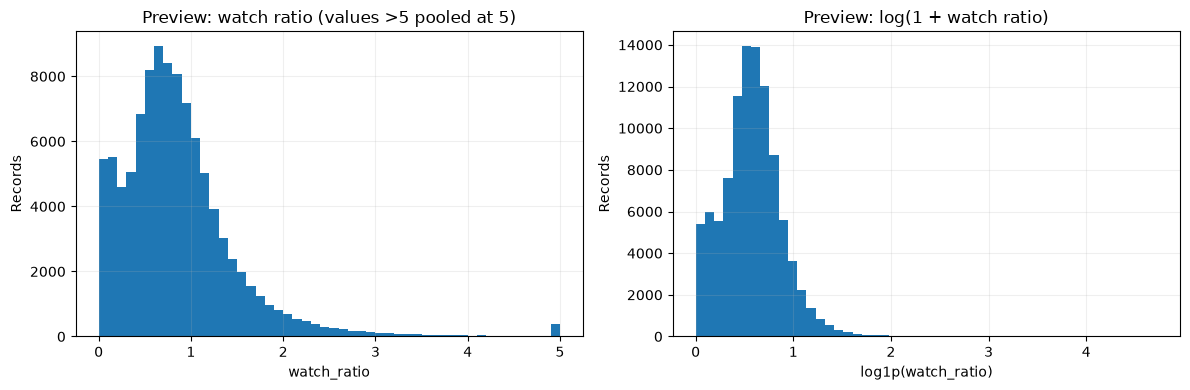

In [6]:
wr = df.loc[np.isfinite(df.watch_ratio) & (df.watch_ratio >= 0), 'watch_ratio']
display(pd.DataFrame([
    {'threshold': t, 'rule': f'watch_ratio > {t}',
     'positive_rows': int((wr > t).sum()), 'positive_pct': (wr > t).mean() * 100}
    for t in [0.5, 1.0, 2.0]
]))
print('Phân vị NumPy:', dict(zip(['p50', 'p90', 'p99'], np.quantile(wr, [0.5, 0.9, 0.99]))))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
wr.clip(upper=5).hist(bins=50, ax=axes[0])
axes[0].set(title='Preview: watch ratio (values >5 pooled at 5)', xlabel='watch_ratio', ylabel='Records')
np.log1p(wr).hist(bins=50, ax=axes[1])
axes[1].set(title='Preview: log(1 + watch ratio)', xlabel='log1p(watch_ratio)', ylabel='Records')
plt.tight_layout()
plt.show()


## 5. Độ dài video và hành vi xem

Video ngắn dễ có ratio cao hơn? So sánh median và tỷ lệ positive theo độ dài.
Đây là liên hệ quan sát, chưa chứng minh độ dài gây ra hành vi.
`corr` chỉ đo quan hệ tuyến tính; ID không nên đưa vào bảng correlation.


,records,median_ratio,strong_interest_rate
duration_band,,,
0-7s,18332,1.226345,0.133919
7-15s,66389,0.774262,0.031722
15-30s,8000,0.372302,0.006250
30-60s,4817,0.163288,0.001038
>60s,2462,0.063638,0.000000


,play_duration,video_duration,watch_ratio
play_duration,1.000000,-0.001268,0.900737
video_duration,-0.001268,1.000000,-0.181298
watch_ratio,0.900737,-0.181298,1.000000


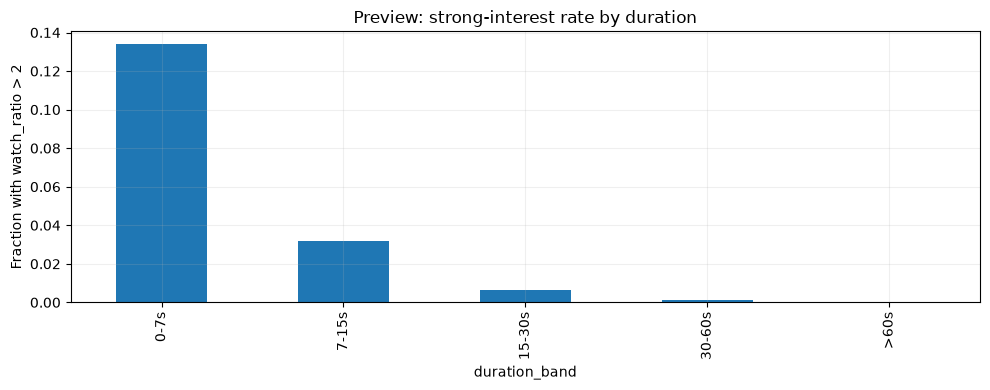

In [7]:
df['video_seconds'] = df.video_duration / 1000
df['duration_band'] = pd.cut(df.video_seconds,
    bins=[0, 7, 15, 30, 60, np.inf], labels=['0-7s', '7-15s', '15-30s', '30-60s', '>60s'])
df['strong_interest'] = df.watch_ratio.gt(2).where(df.watch_ratio.notna())
duration_summary = df.groupby('duration_band', observed=False).agg(
    records=('watch_ratio', 'size'), median_ratio=('watch_ratio', 'median'),
    strong_interest_rate=('strong_interest', 'mean'))
display(duration_summary)
display(df[['play_duration', 'video_duration', 'watch_ratio']].corr())
duration_summary.strong_interest_rate.plot.bar(title='Preview: strong-interest rate by duration')
plt.ylabel('Fraction with watch_ratio > 2')
plt.tight_layout()
plt.show()


\- Xét bảng tương quan : 
- Thời gian xem và độ dài video có hệ số = -0,0013 -> không có quan hệ tuyến tính 
- Thời gian xem và ratio có hệ số = 0,9007 -> có quan hệ tuyến tính dương mạnh
- Độ dài video và ratio có hệ số = -0,1813 -> quan hệ tuyến tính âm yếu.
- Tương quan cao giữa thời gian xem và raio có thể được giải thích 1 phần bởi công thức tính. VD : thời gian xem 10s -> video dài 5s có ratio = 2, video 20s -> ratio = 0,5, video 100s -> ratio = 0,1. Ngưỡng ratio > 2 có thể ngầm ưu tiên video ngắn, vì video càng dài thì cần càng nhiều thời gian xem để đạt ratio cao. Có thể xem xét tách theo nhóm độ dài hoặc xét cả số thời gian xem lẫn ratio cùng lúc thay vì chỉ dựa vào giá trị ratio (vốn có tính thiên kiến ngầm).

## 6. Người dùng, độ phổ biến và thời gian trong preview

`groupby` là công cụ trọng tâm: chuyển từ dòng tương tác sang bảng thống kê người dùng/video.
Số bản ghi của video phản ánh exposure và phản hồi, không tự động là chất lượng.
Thời gian lấy từ chuỗi `time` trong CSV. Không tự đổi sang múi giờ máy.


,records,unique_videos,median_ratio
user_id,,,
137,3326,3326,0.706536
165,3326,3326,0.682588
120,3325,3325,0.669186
41,3324,3324,0.823090
97,3323,3323,0.810283
14,3321,3321,0.821641
51,3319,3319,0.899342
64,3319,3319,1.063740
127,3317,3317,0.611847


,records,unique_users,strong_interest_rate
video_id,,,
131,31,31,0.032258
133,31,31,0.096774
9786,31,31,0.129032
139,31,31,0.096774
142,31,31,0.064516
173,31,31,0.000000
171,31,31,0.161290
170,31,31,0.000000
168,31,31,0.032258


Thời gian parse lỗi: 3787
Khoảng thời gian preview: 2020-07-05 00:01:03.816000 → 2020-09-05 22:41:18.250000


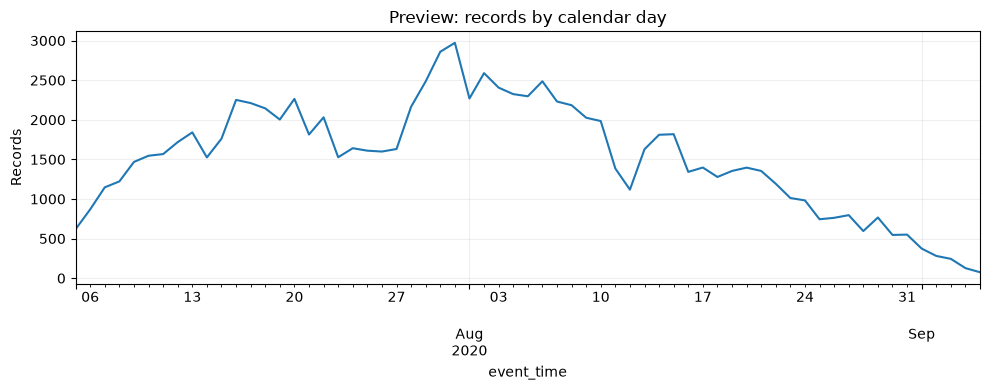

In [8]:
user_preview = df.groupby('user_id').agg(
    records=('video_id', 'size'), unique_videos=('video_id', 'nunique'),
    median_ratio=('watch_ratio', 'median'))
video_preview = df.groupby('video_id').agg(
    records=('user_id', 'size'), unique_users=('user_id', 'nunique'),
    strong_interest_rate=('strong_interest', 'mean'))
display(user_preview.sort_values('records', ascending=False).head(10))
display(video_preview.sort_values('records', ascending=False).head(10))

df['event_time'] = pd.to_datetime(df['time'], errors='coerce')
print('Thời gian parse lỗi:', df.event_time.isna().sum())
print('Khoảng thời gian preview:', df.event_time.min(), '→', df.event_time.max())
df.groupby(df.event_time.dt.floor('D')).size().plot(title='Preview: records by calendar day')
plt.ylabel('Records')
plt.tight_layout()
plt.show()


## 7. Quét toàn bộ bằng chunks: số liệu chính xác với RAM vừa phải

Không tải toàn bộ file lớn vào một DataFrame. Đọc từng khối và cộng thống kê.
Phần này tính số dòng, unique user/video, missing, histogram, tỷ lệ `>2`, bản ghi theo ngày,
theo user/video và theo khoảng độ dài trên **toàn bộ từng file**.

**Không dùng số dòng làm số cặp unique để tính density.** Audit cặp unique có ô riêng.
Không cộng median/quantile của các chunk để lấy median/quantile toàn tập.
Chạy ô này một lần, các ô sau dùng lại kết quả. `RUN_FULL_SCAN=False` sẽ bỏ qua phần nặng.


In [9]:
CORE_COLS = ['user_id', 'video_id', 'play_duration', 'video_duration', 'date', 'watch_ratio']
RATIO_BINS = [0, 0.25, 0.5, 1, 2, 5, 10, np.inf]
DURATION_BINS = [0, 7000, 15000, 30000, 60000, np.inf]

def add_counts(old, new):
    return old.add(new, fill_value=0)

def scan_interactions(path):
    result = {'rows': 0, 'user_counts': pd.Series(dtype='float64'),
              'video_counts': pd.Series(dtype='float64'), 'daily_counts': pd.Series(dtype='float64'),
              'positive_by_video': pd.Series(dtype='float64'),
              'valid_by_video': pd.Series(dtype='float64'),
              'missing': pd.Series(0, index=CORE_COLS, dtype='int64'),
              'ratio_hist': np.zeros(len(RATIO_BINS)-1, dtype='int64'),
              'duration_count': np.zeros(len(DURATION_BINS)-1, dtype='int64'),
              'duration_positive': np.zeros(len(DURATION_BINS)-1, dtype='int64'),
              'valid_ratio': 0, 'positive': 0, 'negative_ratio': 0,
              'nonfinite_ratio': 0, 'invalid_duration': 0, 'formula_mismatch': 0,
              'max_ratio': -np.inf}
    for i, chunk in enumerate(pd.read_csv(path, usecols=CORE_COLS, chunksize=CHUNK_SIZE), start=1):
        result['rows'] += len(chunk)
        result['missing'] += chunk.isna().sum()
        for key, col in [('user_counts', 'user_id'), ('video_counts', 'video_id'), ('daily_counts', 'date')]:
            result[key] = add_counts(result[key], chunk[col].value_counts())
        finite = np.isfinite(chunk.watch_ratio)
        usable = finite & chunk.watch_ratio.ge(0)
        positive = usable & chunk.watch_ratio.gt(2)
        result['valid_ratio'] += int(usable.sum())
        result['positive'] += int(positive.sum())
        result['negative_ratio'] += int(chunk.watch_ratio.lt(0).sum())
        result['nonfinite_ratio'] += int((~finite).sum())
        result['invalid_duration'] += int(chunk.video_duration.le(0).sum())
        result['max_ratio'] = max(result['max_ratio'], chunk.loc[usable, 'watch_ratio'].max())
        result['positive_by_video'] = add_counts(result['positive_by_video'], chunk.loc[positive, 'video_id'].value_counts())
        result['valid_by_video'] = add_counts(result['valid_by_video'], chunk.loc[usable, 'video_id'].value_counts())
        result['ratio_hist'] += np.histogram(chunk.loc[usable, 'watch_ratio'], bins=RATIO_BINS)[0]
        # np.histogram includes lower edge; these duration bands use the same convention.
        duration_ok = usable & chunk.video_duration.gt(0)
        result['duration_count'] += np.histogram(chunk.loc[duration_ok, 'video_duration'], bins=DURATION_BINS)[0]
        result['duration_positive'] += np.histogram(chunk.loc[duration_ok & positive, 'video_duration'], bins=DURATION_BINS)[0]
        formula_ok = finite & chunk.video_duration.gt(0) & chunk.play_duration.notna()
        result['formula_mismatch'] += int((~np.isclose(
            chunk.loc[formula_ok, 'watch_ratio'],
            chunk.loc[formula_ok, 'play_duration'] / chunk.loc[formula_ok, 'video_duration'],
            rtol=1e-5, atol=1e-6)).sum())
        if i % 10 == 0:
            print(path.name, ':', f"{result['rows']:,}", 'dòng')
    for key in ['user_counts', 'video_counts', 'daily_counts', 'positive_by_video', 'valid_by_video']:
        result[key] = result[key].astype('int64')
    return result

full = {}
if RUN_FULL_SCAN:
    for name in ['small_matrix', 'big_matrix']:
        full[name] = scan_interactions(DATA_DIR / f'{name}.csv')
        print('Hoàn tất', name)
else:
    print('Đã bỏ qua full scan. Bật RUN_FULL_SCAN rồi chạy lại từ ô này để có thống kê toàn tập.')


small_matrix.csv : 2,500,000 dòng
Hoàn tất small_matrix
big_matrix.csv : 2,500,000 dòng
big_matrix.csv : 5,000,000 dòng
big_matrix.csv : 7,500,000 dòng
big_matrix.csv : 10,000,000 dòng
big_matrix.csv : 12,500,000 dòng
Hoàn tất big_matrix


In [10]:
if full:
    overview = pd.DataFrame([{
        'matrix': name, 'records': r['rows'], 'users': len(r['user_counts']),
        'videos': len(r['video_counts']), 'valid_ratio_rows': r['valid_ratio'],
        'strong_interest_pct': 100 * r['positive'] / r['valid_ratio'],
        'max_watch_ratio': r['max_ratio'], 'invalid_duration': r['invalid_duration'],
        'formula_mismatch': r['formula_mismatch']
    } for name, r in full.items()])
    display(overview)
    display(pd.DataFrame({name: r['missing'] for name, r in full.items()}))
    display(pd.DataFrame({name: r['ratio_hist'] / r['valid_ratio'] for name, r in full.items()},
        index=['[0,.25)', '[.25,.5)', '[.5,1)', '[1,2)', '[2,5)', '[5,10)', '[10,infinity]']))
    print('Histogram [2,5) gồm cả đúng 2; nhãn positive dùng >2 nên hai số không đồng nhất.')


,matrix,records,users,videos,valid_ratio_rows,strong_interest_pct,max_watch_ratio,invalid_duration,formula_mismatch
0,small_matrix,4676570,1411,3327,4676570,4.643895,571.521428,0,1209
1,big_matrix,12530806,7176,10728,12530806,7.472704,573.457143,0,81


,small_matrix,big_matrix
user_id,0,0
video_id,0,0
play_duration,0,0
video_duration,0,0
date,181992,0
watch_ratio,0,0


,small_matrix,big_matrix
"[0,.25)",0.127221,0.208115
"[.25,.5)",0.145435,0.150921
"[.5,1)",0.403377,0.302739
"[1,2)",0.277516,0.263483
"[2,5)",0.041577,0.065540
"[5,10)",0.003513,0.006553
"[10,infinity]",0.001360,0.002649


Histogram [2,5) gồm cả đúng 2; nhãn positive dùng >2 nên hai số không đồng nhất.


## 8. Long tail và lịch sử: so sánh big với small

Small được thiết kế để gần đầy đủ nên exposure theo video có thể khá đồng đều.
Big phù hợp hơn để xem chênh lệch độ phổ biến.
Đường tích lũy cho biết top x% video chiếm bao nhiêu % bản ghi.
Top 10% ở đây tính theo **số video**, không phải 10% dòng.


small_matrix : top 10% video chiếm 10.05 % bản ghi
big_matrix : top 10% video chiếm 40.72 % bản ghi


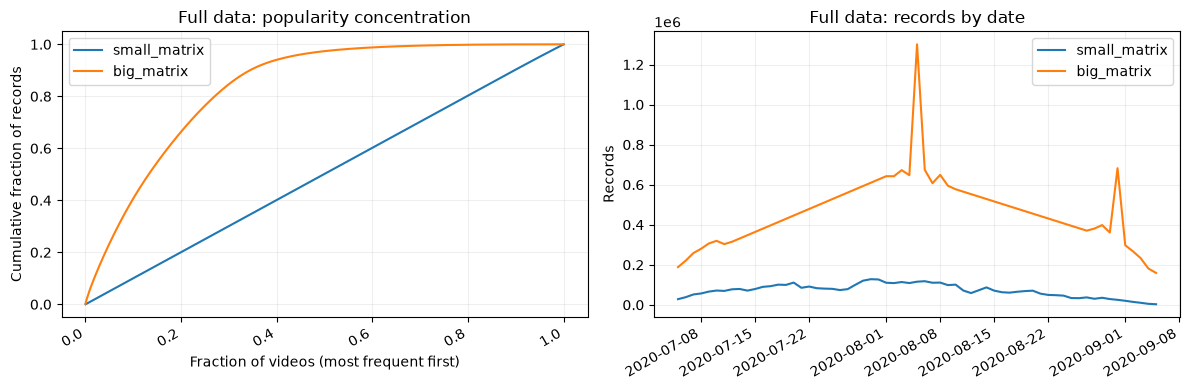

,small_matrix,big_matrix
count,1411.000000,7176.000000
mean,3314.365698,1746.210424
std,6.984852,991.832222
min,3295.000000,100.000000
25%,3309.000000,883.000000
50%,3315.000000,1846.500000
75%,3320.000000,2461.000000
max,3327.000000,16015.000000


,small_matrix,big_matrix
"(0,7)s",0.130033,0.181652
"[7,15)s",0.033388,0.058362
"[15,30)s",0.008192,0.021295
"[30,60)s",0.001988,0.005911
"[60,infinity)s",0.000554,0.002077


In [11]:
if full:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for name, r in full.items():
        counts = r['video_counts'].sort_values(ascending=False)
        x = np.arange(1, len(counts)+1) / len(counts)
        axes[0].plot(x, counts.cumsum() / counts.sum(), label=name)
        top_n = max(1, int(np.ceil(len(counts) * 0.10)))
        print(name, ': top 10% video chiếm', round(100*counts.iloc[:top_n].sum()/counts.sum(), 2), '% bản ghi')
        daily = r['daily_counts'].sort_index().copy()
        daily.index = pd.to_datetime(daily.index.astype('int64').astype(str), format='%Y%m%d')
        axes[1].plot(daily.index, daily.values, label=name)
    axes[0].set(title='Full data: popularity concentration', xlabel='Fraction of videos (most frequent first)', ylabel='Cumulative fraction of records')
    axes[1].set(title='Full data: records by date', ylabel='Records')
    for ax in axes:
        ax.legend()
    fig.autofmt_xdate()
    plt.tight_layout()
    plt.show()
    display(pd.DataFrame({name: r['user_counts'].describe() for name, r in full.items()}))
    display(pd.DataFrame({name: np.divide(r['duration_positive'], r['duration_count'],
        out=np.full(5, np.nan), where=r['duration_count'] > 0) for name, r in full.items()},
        index=['(0,7)s', '[7,15)s', '[15,30)s', '[30,60)s', '[60,infinity)s']))


## 9. Audit cặp unique, density và overlap (tùy chọn)

Đọc thêm hai cột ID của mỗi file. Dùng NumPy mã hóa cặp và `unique`, thay vì tạo ma trận dense.
Phần này cần thêm RAM và lượt đọc đĩa. Số dòng / (users × videos) **chỉ là density nếu không có cặp lặp**.
Audit giúp kiểm chứng hai ma trận không trùng cặp; không chứng minh được train xảy ra trước test.


In [12]:
if RUN_PAIR_AUDIT:
    if not full:
        raise ValueError('Bật RUN_FULL_SCAN và chạy phần 7 trước.')
    stride = int(max(r['video_counts'].index.max() for r in full.values())) + 1
    pairs = {}
    audit = []
    for name, r in full.items():
        parts = []
        for chunk in pd.read_csv(DATA_DIR / f'{name}.csv', usecols=['user_id', 'video_id'], chunksize=CHUNK_SIZE):
            assert chunk.notna().all().all(), 'ID thiếu: cần xử lý trước khi mã hóa cặp'
            u = chunk.user_id.to_numpy(dtype=np.int64)
            v = chunk.video_id.to_numpy(dtype=np.int64)
            assert (u >= 0).all() and (v >= 0).all() and (v < stride).all()
            parts.append(u * stride + v)
        pairs[name] = np.unique(np.concatenate(parts))
        del parts
        n_pairs = len(pairs[name])
        audit.append({'matrix': name, 'unique_pairs': n_pairs,
            'repeat_records': r['rows']-n_pairs,
            'density_pct': 100*n_pairs/(len(r['user_counts'])*len(r['video_counts']))})
    display(pd.DataFrame(audit))
    print('Cặp overlap:', len(np.intersect1d(pairs['small_matrix'], pairs['big_matrix'], assume_unique=True)))
    del pairs
else:
    print('Audit cặp đầy đủ chưa chạy. Không suy density từ số dòng.')


,matrix,unique_pairs,repeat_records,density_pct
0,small_matrix,4676570,0,99.620249
1,big_matrix,10300969,2229837,13.380640


Cặp overlap: 0


## 10. Metadata cho content-based và hybrid

Đọc category/tag/caption. Chuỗi dạng `[27, 9]` cần parse thành list rồi `explode`.
Dùng `ast.literal_eval`, không dùng `eval`. Không nối trực tiếp nhiều bảng one-to-many vào interaction:
một dòng có thể bị nhân lên và làm sai thống kê.
`merge(validate=...)` giúp phát hiện quan hệ nối sai. `UNKNOWN` cũng là thiếu về mặt ngữ nghĩa,
dù `isna()` trả về False.

**Phát hiện ở file caption hiện có:** dấu CR trong văn bản khiến parser mặc định báo buffer overflow,
và `engine='python'` tạo 4 dòng giả. File dùng LF làm kết thúc bản ghi nên đặt
`lineterminator='\n'`. Kiểm tra ID sau đọc, không dùng `on_bad_lines='skip'` để che vấn đề.


In [13]:
categories = pd.read_csv(DATA_DIR / 'item_categories.csv')
users = pd.read_csv(DATA_DIR / 'user_features.csv')
captions = pd.read_csv(DATA_DIR / 'kuairec_caption_category.csv', lineterminator='\n')
assert captions.video_id.notna().all() and captions.video_id.is_unique
assert pd.api.types.is_integer_dtype(captions.video_id)
for name, table in [('categories', categories), ('users', users), ('captions', captions)]:
    print(name, table.shape)
    display(table.head(3))

categories['tags'] = categories.feat.map(ast.literal_eval)
tag_long = categories[['video_id', 'tags']].explode('tags').dropna(subset=['tags'])
tag_long['tags'] = tag_long.tags.astype('int64')
display(tag_long.tags.value_counts().rename('videos_per_tag').head(15).to_frame())
display(categories.tags.map(len).value_counts().sort_index().rename('videos').to_frame())

caption_missing = pd.DataFrame({
    'null_pct': captions.isna().mean()*100,
    'unknown_or_empty_pct': captions.apply(lambda s:
        s.astype('string').str.strip().isin(['UNKNOWN', '']).mean()*100)
})
display(caption_missing)
display(captions.first_level_category_name.value_counts().head(15))


categories (10728, 2)


,video_id,feat
0,0,[8]
1,1,"[27, 9]"
2,2,[9]


users (7176, 31)


,user_id,user_active_degree,is_lowactive_period,is_live_streamer,is_video_author,follow_user_num,follow_user_num_range,...,onehot_feat11,onehot_feat12,onehot_feat13,onehot_feat14,onehot_feat15,onehot_feat16,onehot_feat17
0,0,high_active,0,0,0,5,"(0,10]",...,0,0.0,0.0,0.0,0.0,0.0,0.0
1,1,full_active,0,0,0,386,"(250,500]",...,0,0.0,0.0,0.0,0.0,0.0,0.0
2,2,full_active,0,0,0,27,"(10,50]",...,0,0.0,0.0,0.0,0.0,0.0,0.0


captions (10728, 10)


,video_id,manual_cover_text,caption,topic_tag,first_level_category_id,first_level_category_name,second_level_category_id,second_level_category_name,third_level_category_id,third_level_category_name
0,0,UNKNOWN,精神小伙路难走 程哥你狗粮慢点撒,[],8,颜值,673,颜值随拍,-124,UNKNOWN
1,1,UNKNOWN,NaN,[],27,高新数码,-124,UNKNOWN,-124,UNKNOWN
2,2,UNKNOWN,晚饭后，运动一下！,[],9,喜剧,727,搞笑互动,-124,UNKNOWN


,videos_per_tag
tags,
11,2027
28,1360
8,1112
5,964
6,912
9,696
19,686
12,534
7,503


,videos
tags,
1,8970
2,1562
3,185
4,11


,null_pct,unknown_or_empty_pct
video_id,0.0000,0.000000
manual_cover_text,0.0000,62.406786
caption,12.6305,0.009321
topic_tag,0.0000,0.000000
first_level_category_id,0.0000,0.000000
first_level_category_name,0.0000,0.372856
second_level_category_id,0.0000,0.000000
second_level_category_name,0.0000,33.398583
third_level_category_id,0.0000,0.000000
third_level_category_name,0.0000,63.683818


first_level_category_name
民生资讯    1095
时尚      1034
其他       914
颜值       824
情感       532
美食       475
明星娱乐     473
舞蹈       422
生活       417
自拍       379
喜剧       366
亲子       363
运动       317
艺术       309
二次元      257
Name: count, dtype: int64

In [14]:
enriched = df.merge(categories[['video_id', 'tags']], on='video_id', how='left', validate='many_to_one')
enriched = enriched.merge(captions[['video_id', 'caption', 'first_level_category_name']],
    on='video_id', how='left', validate='many_to_one')
assert len(enriched) == len(df)
print('Preview: tỷ lệ thiếu tag sau join =', enriched.tags.isna().mean())
display(enriched[['user_id', 'video_id', 'watch_ratio', 'tags', 'caption', 'first_level_category_name']].head())

if full:
    stats = pd.DataFrame({
        'records': full['big_matrix']['video_counts'],
        'valid_ratio_records': full['big_matrix']['valid_by_video'],
        'positive_records': full['big_matrix']['positive_by_video']
    }).fillna({'positive_records': 0}).rename_axis('video_id').reset_index()
    content_stats = captions.merge(stats, on='video_id', how='left', validate='one_to_one')
    by_category = content_stats.groupby('first_level_category_name').agg(
        videos=('video_id', 'nunique'), records=('records', 'sum'),
        valid_ratio_records=('valid_ratio_records', 'sum'), positives=('positive_records', 'sum'))
    by_category['positive_rate'] = by_category.positives / by_category.valid_ratio_records.replace(0, np.nan)
    display(by_category.sort_values('records', ascending=False).head(15))
    print('Tỷ lệ theo bản ghi, không phải trung bình tỷ lệ của từng video; đây là EDA, không phải feature train.')


Preview: tỷ lệ thiếu tag sau join = 0.0


,user_id,video_id,watch_ratio,tags,caption,first_level_category_name
0,14,148,0.722103,"[11, 28, 19]",美60岁奶奶与21少年一见钟情，兴奋分享初次体验，称：升华了感情！ @推广小助手(O4030...,情感
1,14,183,1.907377,[28],合肥高铁南站，他带了瓶开过封的茅台被拦下，酒值4000元他舍不得扔，就一饮而尽。,民生资讯
2,14,3649,2.063311,[9],美女裤兜上插“菜刀”吓坏旁人 哦豁，拔出来才发现是手机壳,民生资讯
3,14,5262,0.566388,[25],生了个洋娃娃，婆婆非要发出来给大家看看，看看有没有人点赞，一分钟催我看一下，一分钟催我看一下😂,时尚
4,14,8234,0.418364,[6],#郝劭文 小时候火遍全国，跟释小龙一起成为一代人最喜爱的童星，长大后却没能大火，你还记得那个...,明星娱乐


,videos,records,valid_ratio_records,positives,positive_rate
first_level_category_name,,,,,
民生资讯,1095,2390185,2390185,226516.0,0.094769
颜值,824,1132144,1132144,96112.0,0.084894
明星娱乐,473,801031,801031,42473.0,0.053023
其他,914,717004,717004,57570.0,0.080292
时尚,1034,622058,622058,52627.0,0.084601
运动,317,504565,504565,44240.0,0.087679
舞蹈,422,499760,499760,29753.0,0.059535
美食,475,475583,475583,24604.0,0.051734
生活,417,467616,467616,35308.0,0.075506


Tỷ lệ theo bản ghi, không phải trung bình tỷ lệ của từng video; đây là EDA, không phải feature train.


## 11. Xem sở thích của một người: bước đầu cho content-based

Chọn user có nhiều bản ghi nhất trong preview để dễ quan sát. Bạn có thể đổi `USER_ID`.
Một video có nhiều tag được tính vào nhiều nhóm nên tổng số membership có thể lớn hơn số tương tác.
Hồ sơ này chỉ dùng phần preview, chưa đủ đại diện lịch sử đầy đủ của người đó.


,video_id,watch_ratio,caption,first_level_category_name
76128,1305,3.085239,初学，不知道这是啥动作 @玩轮滑e段子手☞王☜能能(O7469221),运动
73065,314,2.454190,#2020高考季 #快手助推 #作品推广 #申请热门 #感谢快手我要上热门,时尚
76143,6222,2.446171,#排球 4号位打一个😉,运动
73123,154,2.373540,NaN,运动
74506,847,2.369872,别说结尾了，这开头都没猜着啊。,民生资讯
74735,7383,2.367134,NaN,运动
73877,4040,2.311933,这才叫过弯！！！#快说车,汽车
73298,5525,2.290909,540～3A,运动
73764,600,2.271746,#作品推广 #做任务赢曝光 #粉丝脚垫 #喜欢的朋友们给个双击给个评论感谢大家的支持 #手机...,汽车
75984,9178,2.153599,#成龙 七夕节快乐,明星娱乐


,memberships,median_ratio,strong_interest_rate
tags,,,
28,849,0.803890,0.001178
8,506,0.745442,0.001976
6,451,0.632291,0.002217
11,426,0.713796,0.000000
9,332,0.664860,0.003012
26,330,0.685513,0.000000
7,208,0.823164,0.024038
17,189,0.771864,0.000000
1,163,0.683642,0.000000


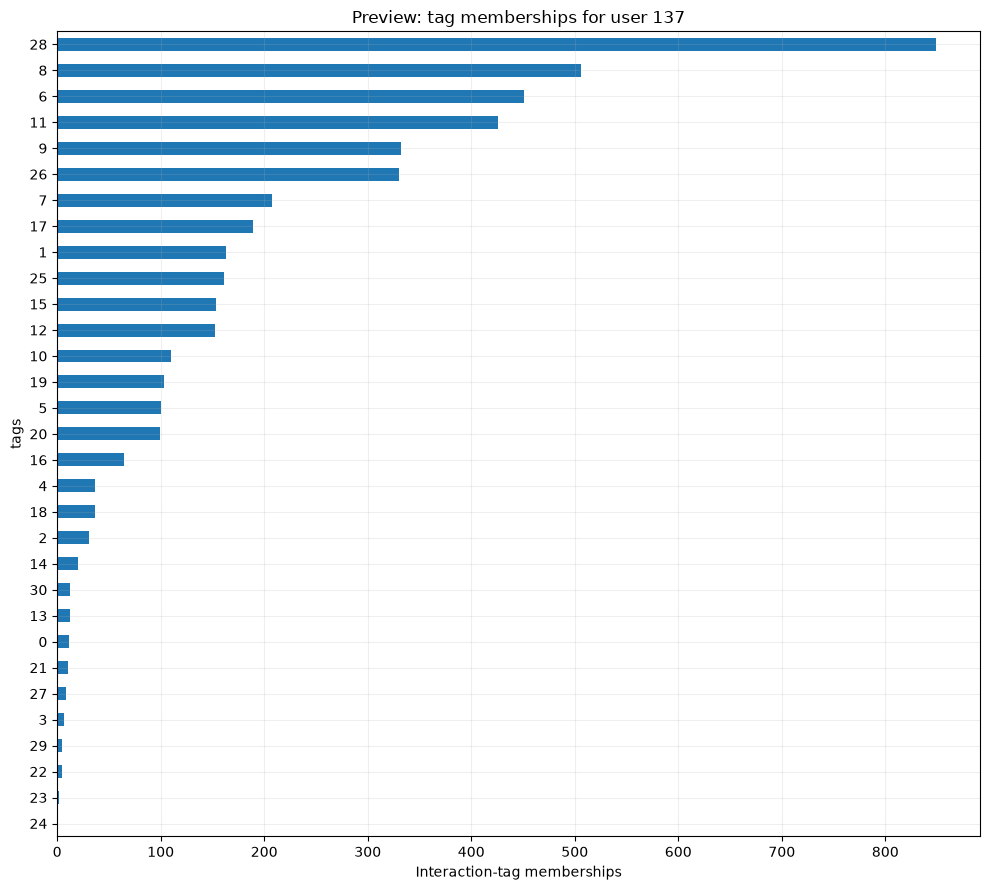

In [15]:
USER_ID = int(df.user_id.value_counts().index[0])
history = enriched.loc[enriched.user_id.eq(USER_ID)].copy()
display(history.sort_values('watch_ratio', ascending=False)[
    ['video_id', 'watch_ratio', 'caption', 'first_level_category_name']].head(10))
memberships = history.explode('tags').dropna(subset=['tags'])
interest_profile = memberships.groupby('tags').agg(
    memberships=('video_id', 'size'), median_ratio=('watch_ratio', 'median'),
    strong_interest_rate=('strong_interest', 'mean'))
display(interest_profile.sort_values('memberships', ascending=False))
interest_profile.memberships.sort_values().plot.barh(figsize=(10, 9), title=f'Preview: tag memberships for user {USER_ID}')
plt.xlabel('Interaction-tag memberships')
plt.tight_layout()
plt.show()


## 12. User metadata, social graph và video–ngày

Social graph chỉ có một phần người dùng có danh sách bạn trong tập, không đủ thay cho toàn bộ follow graph.
Không mặc định `author_id` dùng cùng namespace với `user_id`.
Like/share/follow trong `item_daily_features` là thống kê video–ngày, **không phải nhãn của từng user**.


In [16]:
display(users[['user_active_degree', 'is_video_author']].value_counts().head(10))
display(users.isna().mean().sort_values(ascending=False).head(10).rename('missing_fraction'))
social = pd.read_csv(DATA_DIR / 'social_network.csv')
social['friends'] = social.friend_list.map(ast.literal_eval)
display(social.head())
print('User có ít nhất một bạn trong file:', social.loc[social.friends.map(len).gt(0), 'user_id'].nunique())
display(social.friends.map(len).describe())

DAILY_COLS = ['video_id', 'date', 'author_id', 'upload_dt', 'show_cnt', 'play_cnt',
    'like_cnt', 'share_cnt', 'follow_cnt', 'collect_cnt']
daily = pd.read_csv(DATA_DIR / 'item_daily_features.csv', usecols=DAILY_COLS)
display(daily.head())
print('Daily shape:', daily.shape)
print('Video-date lặp:', daily.duplicated(['video_id', 'date']).sum())
display(daily.isna().mean().rename('missing_fraction').to_frame())
display(daily[['show_cnt', 'play_cnt', 'like_cnt', 'share_cnt', 'follow_cnt']].describe())


user_active_degree  is_video_author
full_active         0                  5040
                    1                  1052
high_active         0                   793
                    1                   145
UNKNOWN             0                   101
middle_active       0                    25
UNKNOWN             1                    17
middle_active       1                     3
Name: count, dtype: int64

onehot_feat4          0.028010
onehot_feat12         0.010730
onehot_feat13         0.010452
onehot_feat14         0.010452
onehot_feat17         0.010312
onehot_feat16         0.010312
onehot_feat15         0.010312
fans_user_num         0.000000
user_id               0.000000
user_active_degree    0.000000
Name: missing_fraction, dtype: float64

,user_id,friend_list,friends
0,3371,[2975],[2975]
1,24,[2665],[2665]
2,4402,[38],[38]
3,4295,[4694],[4694]
4,7087,[7117],[7117]


User có ít nhất một bạn trong file: 472


count    472.000000
mean       1.419492
std        0.853295
min        1.000000
25%        1.000000
50%        1.000000
75%        2.000000
max        5.000000
Name: friends, dtype: float64

,video_id,date,author_id,upload_dt,show_cnt,play_cnt,like_cnt,follow_cnt,share_cnt,collect_cnt
0,0,20200705,3309,2020-03-30,14665,10141,573,284,2,NaN
1,0,20200706,3309,2020-03-30,10883,7321,302,201,1,NaN
2,0,20200707,3309,2020-03-30,7842,4757,205,131,1,NaN
3,0,20200708,3309,2020-03-30,8916,5172,297,179,2,NaN
4,0,20200709,3309,2020-03-30,8502,5392,307,186,0,NaN


Daily shape: (343341, 10)
Video-date lặp: 0


,missing_fraction
video_id,0.000000
date,0.000000
author_id,0.000000
upload_dt,0.000000
show_cnt,0.000000
play_cnt,0.000000
like_cnt,0.000000
follow_cnt,0.000000
share_cnt,0.000000
collect_cnt,0.202956


,show_cnt,play_cnt,like_cnt,share_cnt,follow_cnt
count,3.433410e+05,3.433410e+05,3.433410e+05,343341.000000,343341.000000
mean,9.424580e+04,9.418781e+04,2.781109e+03,80.380860,302.643914
std,5.761700e+05,5.933298e+05,1.869603e+04,1284.173127,2822.293469
min,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000
25%,5.500000e+01,1.400000e+01,0.000000e+00,0.000000,0.000000
50%,1.328000e+03,6.280000e+02,9.000000e+00,0.000000,1.000000
75%,2.419000e+04,2.067100e+04,4.210000e+02,3.000000,39.000000
max,4.218154e+07,4.116795e+07,2.673037e+06,299286.000000,493711.000000


## 13. Feature theo thời gian: tránh đọc tương lai

Ví dụ bên dưới chỉ dùng thống kê **ngày trước ngày tương tác**: nối video + ngày trước.
Không dùng tổng like của cùng ngày để dự đoán một sự kiện vào buổi sáng ngày đó.
Nếu dùng as-of join cho ngày gần nhất, cần sắp xếp đúng và xác định độ trễ dữ liệu.
Metadata được bổ sung năm 2024 có thể không phản ánh đúng thời điểm năm 2020;
phân biệt thí nghiệm sở thích tĩnh với mô phỏng lịch sử nghiêm ngặt.


In [17]:
events = df[['user_id', 'video_id', 'event_time']].copy()
events['previous_day'] = events.event_time.dt.normalize() - pd.Timedelta(days=1)
previous_daily = daily[['video_id', 'date', 'like_cnt', 'show_cnt']].copy()
previous_daily['previous_day'] = pd.to_datetime(previous_daily['date'].astype('int64').astype(str), format='%Y%m%d')
previous_daily = previous_daily.drop(columns='date').rename(columns={
    'like_cnt': 'previous_day_like_cnt', 'show_cnt': 'previous_day_show_cnt'})
safe_features = events.merge(previous_daily, on=['video_id', 'previous_day'],
    how='left', validate='many_to_one')
display(safe_features.head())
print('Thiếu thống kê ngày trước:', safe_features.previous_day_show_cnt.isna().mean())
print('Giữ NaN nếu thiếu. Không mặc định thiếu = 0 lượt hiển thị.')


,user_id,video_id,event_time,previous_day,previous_day_like_cnt,previous_day_show_cnt
0,14,148,2020-07-05 05:27:48.378,2020-07-04,NaN,NaN
1,14,183,2020-07-05 05:28:00.057,2020-07-04,NaN,NaN
2,14,3649,2020-07-05 05:29:09.479,2020-07-04,NaN,NaN
3,14,5262,2020-07-05 05:30:43.285,2020-07-04,NaN,NaN
4,14,8234,2020-07-05 05:35:43.459,2020-07-04,NaN,NaN


Thiếu thống kê ngày trước: 0.13015
Giữ NaN nếu thiếu. Không mặc định thiếu = 0 lượt hiển thị.


## 14. Viết kết luận EDA và làm bài tập

Điền dựa vào kết quả bạn thấy, ghi rõ toàn tập hay preview:

1. Một dòng interaction là gì? Có cặp lặp không (audit đã chạy chưa)?
2. Có cột thiếu, giá trị không hợp lệ hay ratio cực lớn nào cần kiểm tra?
3. Với ngưỡng `>2`, positive chiếm bao nhiêu? Nếu đổi ngưỡng thì sao?
4. Big và small khác nhau thế nào về exposure và độ phổ biến?
5. Ratio và độ dài có liên hệ gì? Cần biến đổi/cap nhãn thế nào?
6. Bao nhiêu video thiếu caption/tag? Content-based sẽ fallback ra sao?
7. Hai người có cùng chủ đề nhưng hành vi khác nhau không? Hybrid giúp gì?
8. Feature nào có thể biết tại thời điểm gợi ý, feature nào có nguy cơ đọc tương lai?

**Bài tập pandas:** đổi `USER_ID`; tìm 10 video có tỷ lệ quan tâm mạnh cao nhất với ít nhất 100
bản ghi hợp lệ; so sánh top theo exposure và theo tỷ lệ phản hồi. Không gọi đây là kết quả mô hình.

**Bước tiếp:** dùng tag/caption làm content baseline, collaborative làm baseline khác, rồi hybrid.
Không dùng nhãn của tập test hoặc hồ sơ tạo từ toàn bộ lịch sử để đánh giá dự đoán quá khứ.


In [18]:
# Bài tập có gợi ý; thử tự viết trước rồi chạy.
if full:
    r = full['big_matrix']
    video_eda = pd.DataFrame({'exposures': r['video_counts'],
        'valid_records': r['valid_by_video'], 'positive_records': r['positive_by_video']})
    video_eda['positive_records'] = video_eda.positive_records.fillna(0)
    video_eda['positive_rate'] = video_eda.positive_records / video_eda.valid_records.replace(0, np.nan)
    display(video_eda.query('valid_records >= 100').sort_values('positive_rate', ascending=False).head(10))


,exposures,valid_records,positive_records,positive_rate
video_id,,,,
1654,497,497,388.0,0.780684
10598,306,306,224.0,0.732026
7644,105,105,76.0,0.723810
6463,1105,1105,778.0,0.704072
4546,489,489,344.0,0.703476
10028,1105,1105,772.0,0.698643
10706,907,907,629.0,0.693495
4374,954,954,660.0,0.691824
3367,1132,1132,772.0,0.681979


## Phát hiện đã kiểm chứng trên dữ liệu của bạn

- Small: 4.676.570 dòng và cặp unique; density 99,620%; nhãn `watch_ratio > 2` chiếm 4,64%.
- Big: 12.530.806 dòng, 10.300.969 cặp unique. Có 2.229.837 dòng ngoài lần xuất hiện đầu của cặp.
  Density theo unique pairs là 13,381%. Con số 16,3% công bố tương ứng mật độ theo số bản ghi;
  cần nêu rõ định nghĩa khi so sánh. Không tự xóa các lượt lặp: có thể là tương tác ở thời điểm khác.
- Hai ma trận không có cặp user–video giao nhau (audit toàn bộ).
- Small có 181.992 dòng thiếu `date` (3,89%). Các ví dụ kiểm tra cũng thiếu `time` và `timestamp`.
  Biểu đồ ngày loại những dòng thiếu ngày, nên không bao phủ toàn bộ tương tác.
  Không tự gán ngày để làm temporal split. Muốn biết số thiếu `time`/`timestamp` toàn tập, quét thêm hai cột đó.
- Có 1.209 dòng ở small và 81 dòng ở big lệch công thức ratio tại `rtol=1e-5`, `atol=1e-6`.
  Kiểm tra độ lệch tuyệt đối/tương đối và tài liệu trước khi quyết định dùng nhãn có sẵn hay tính lại.
- Top 10% video theo exposure chiếm 40,72% bản ghi big, so với 10,05% ở small.
- Caption cần `lineterminator='\n'` để giữ đúng 10.728 video. Đổi sang Python parser đơn thuần
  tạo 4 dòng giả; kiểm tra ID giúp nhận ra vấn đề.

Các số này là kết quả EDA, chưa phải kết quả chất lượng mô hình.
